# 01 · Exploratory Data Analysis and Data Preparation

**Project:** Kaggle — House Prices: Advanced Regression Techniques

**Goal of this notebook:** understand the data, clean it, create new features and save processed `train` and `test` files for `02_Models.ipynb`.

Pipeline: `data/raw` → **01_EDA** → `data/processed` → 02_Models → `submissions`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42
RAW = "../data/raw/"
PROCESSED = "../data/processed/"
FIG = "../results/figures/"

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## B1 · First look

Load `train.csv` (1460 houses with `SalePrice`) and `test.csv` (1459 houses without it). Show size, column types and statistics.

In [27]:
train = pd.read_csv(RAW + "train.csv")
test = pd.read_csv(RAW + "test.csv")

print("train:", train.shape)
print("test: ", test.shape)
train.head()

train: (1460, 81)
test:  (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print(train.dtypes.value_counts())
num_cols = train.select_dtypes(include="number").columns.drop(["Id", "SalePrice"]).tolist()
cat_cols = train.select_dtypes(exclude="number").columns.tolist()
print("numeric columns:", len(num_cols))
print("categorical columns:", len(cat_cols))

object     43
int64      35
float64     3
Name: count, dtype: int64
numeric columns: 36
categorical columns: 43


In [4]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [5]:
train[cat_cols].describe().T

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


**Observations**
- 79 features + `Id` + target `SalePrice`.
- 36 numeric and 43 categorical (text) columns.
- `MSSubClass` is stored as a number but it is really a category (type of dwelling) — I treat it as categorical later.

## B2 · Target: `SalePrice`

The Kaggle metric is RMSE on **log(SalePrice)**, so I look at the price and at its log.

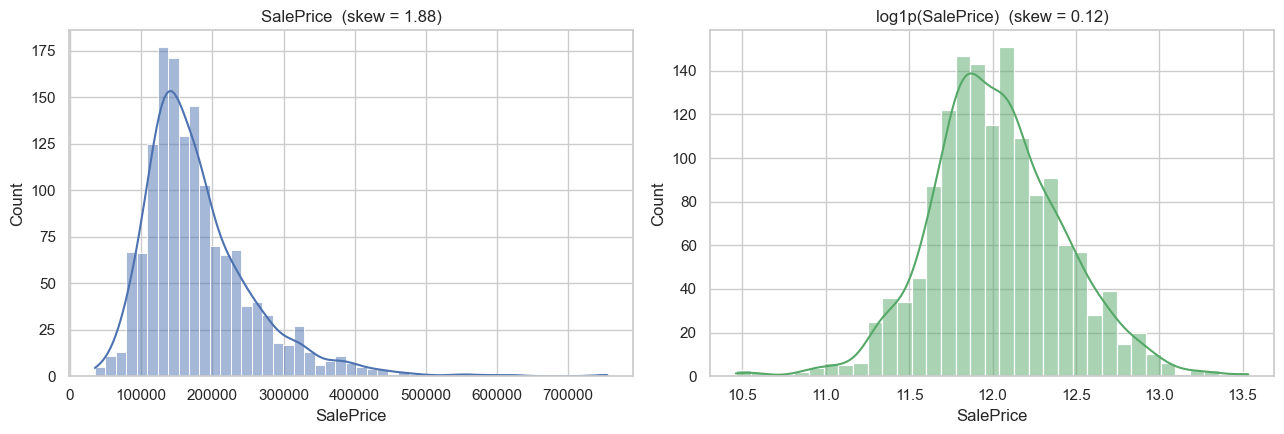

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(train["SalePrice"], kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"SalePrice  (skew = {train['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(train["SalePrice"]), kde=True, ax=axes[1], color="#55A868")
axes[1].set_title(f"log1p(SalePrice)  (skew = {np.log1p(train['SalePrice']).skew():.2f})")
plt.tight_layout()
plt.savefig(FIG + "01_target_distribution.png", dpi=120)
plt.show()

train["SalePrice"].describe()

**Observations**
- `SalePrice` is right-skewed (skew ≈ 1.88): many average houses, few very expensive ones.
- After `log1p` the distribution is almost normal (skew ≈ 0.12).
- So the models will learn **y = log1p(SalePrice)**. This matches the Kaggle metric and helps linear models. Predictions are turned back into dollars with `expm1`.

## B3 · Missing values

First I combine train and test (without the target) so that both are cleaned **the same way**. All fill values (median, mode) are computed **on train only**.

In [7]:
n_train = len(train)
y = train["SalePrice"].copy()
train_ids = train["Id"].copy()
test_ids = test["Id"].copy()

full = pd.concat([train.drop(columns="SalePrice"), test], axis=0, ignore_index=True)

def missing_table(df):
    m = df.isna().sum()
    m = m[m > 0].sort_values(ascending=False)
    return pd.DataFrame({"missing": m, "percent": (m / len(df) * 100).round(1)})

miss_train = missing_table(full.iloc[:n_train])
miss_test = missing_table(full.iloc[n_train:])
miss = miss_train.join(miss_test, how="outer", lsuffix="_train", rsuffix="_test").fillna(0)
miss = miss.sort_values("missing_train", ascending=False)
print("columns with missing values:", len(miss))
miss

columns with missing values: 34


,missing_train,percent_train,missing_test,percent_test
PoolQC,1453.0,99.5,1456.0,99.8
MiscFeature,1406.0,96.3,1408.0,96.5
Alley,1369.0,93.8,1352.0,92.7
Fence,1179.0,80.8,1169.0,80.1
MasVnrType,872.0,59.7,894.0,61.3
FireplaceQu,690.0,47.3,730.0,50.0
LotFrontage,259.0,17.7,227.0,15.6
GarageYrBlt,81.0,5.5,78.0,5.3
GarageQual,81.0,5.5,78.0,5.3
GarageFinish,81.0,5.5,78.0,5.3


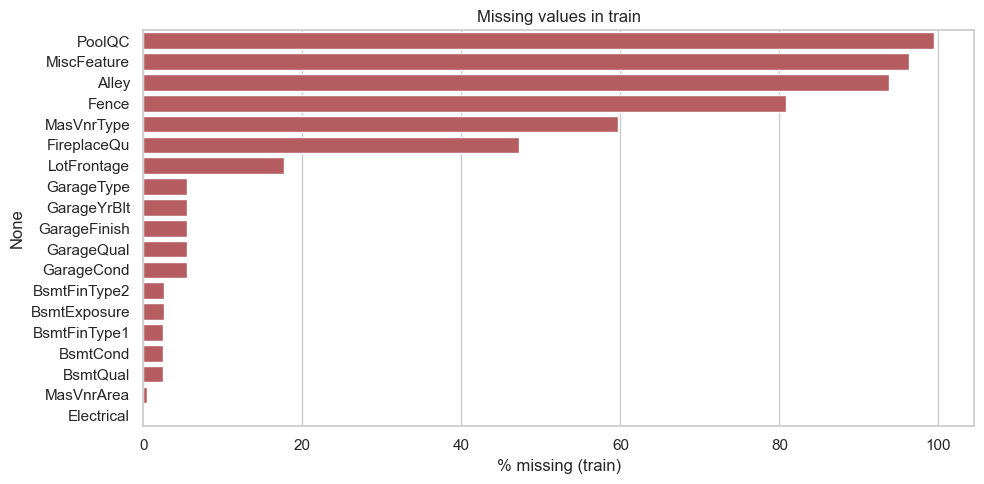

In [8]:
top = miss_train.head(20)
plt.figure(figsize=(10, 5))
sns.barplot(x=top["percent"], y=top.index, color="#C44E52")
plt.xlabel("% missing (train)")
plt.title("Missing values in train")
plt.tight_layout()
plt.savefig(FIG + "02_missing_values.png", dpi=120)
plt.show()

**How I fill them** (based on `data_description.txt`):

| Group | Columns | Fill with | Why |
|---|---|---|---|
| NA means "no such thing" | PoolQC, MiscFeature, Alley, Fence, FireplaceQu, Garage\*, Bsmt\* (text), MasVnrType | `"None"` | e.g. NA in `PoolQC` = no pool. pandas also reads the text `None` in `MasVnrType` as missing — it means "no veneer". |
| Area / count of a missing thing | GarageArea, GarageCars, BsmtFinSF1/2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath, MasVnrArea | `0` | no garage → 0 m² garage |
| GarageYrBlt | GarageYrBlt | `YearBuilt` | no garage year → use the house year (0 would be a fake year) |
| LotFrontage | LotFrontage | median of the same `Neighborhood` (train) | houses in one neighborhood have similar lots |
| Functional | Functional | `"Typ"` | the description says "assume typical unless deductions are warranted" |
| A few random gaps | MSZoning, Utilities, Electrical, KitchenQual, Exterior1st/2nd, SaleType | most frequent value in train | only 1–4 rows each |

In [9]:
none_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
             "GarageType", "GarageFinish", "GarageQual", "GarageCond",
             "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
             "MasVnrType"]
zero_cols = ["GarageArea", "GarageCars", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
             "TotalBsmtSF", "BsmtFullBath", "BsmtHalfBath", "MasVnrArea"]
mode_cols = ["MSZoning", "Utilities", "Electrical", "KitchenQual",
             "Exterior1st", "Exterior2nd", "SaleType"]

full[none_cols] = full[none_cols].fillna("None")
full[zero_cols] = full[zero_cols].fillna(0)
full["GarageYrBlt"] = full["GarageYrBlt"].fillna(full["YearBuilt"])
full["Functional"] = full["Functional"].fillna("Typ")

train_part = full.iloc[:n_train]
lot_median = train_part.groupby("Neighborhood")["LotFrontage"].median()
full["LotFrontage"] = full["LotFrontage"].fillna(full["Neighborhood"].map(lot_median))
full["LotFrontage"] = full["LotFrontage"].fillna(train_part["LotFrontage"].median())

for c in mode_cols:
    full[c] = full[c].fillna(train_part[c].mode()[0])

print("missing values left in train:", full.iloc[:n_train].isna().sum().sum())
print("missing values left in test: ", full.iloc[n_train:].isna().sum().sum())

missing values left in train: 0
missing values left in test:  0


## B4 · Visualizations

### B4.1 Numeric columns — distributions

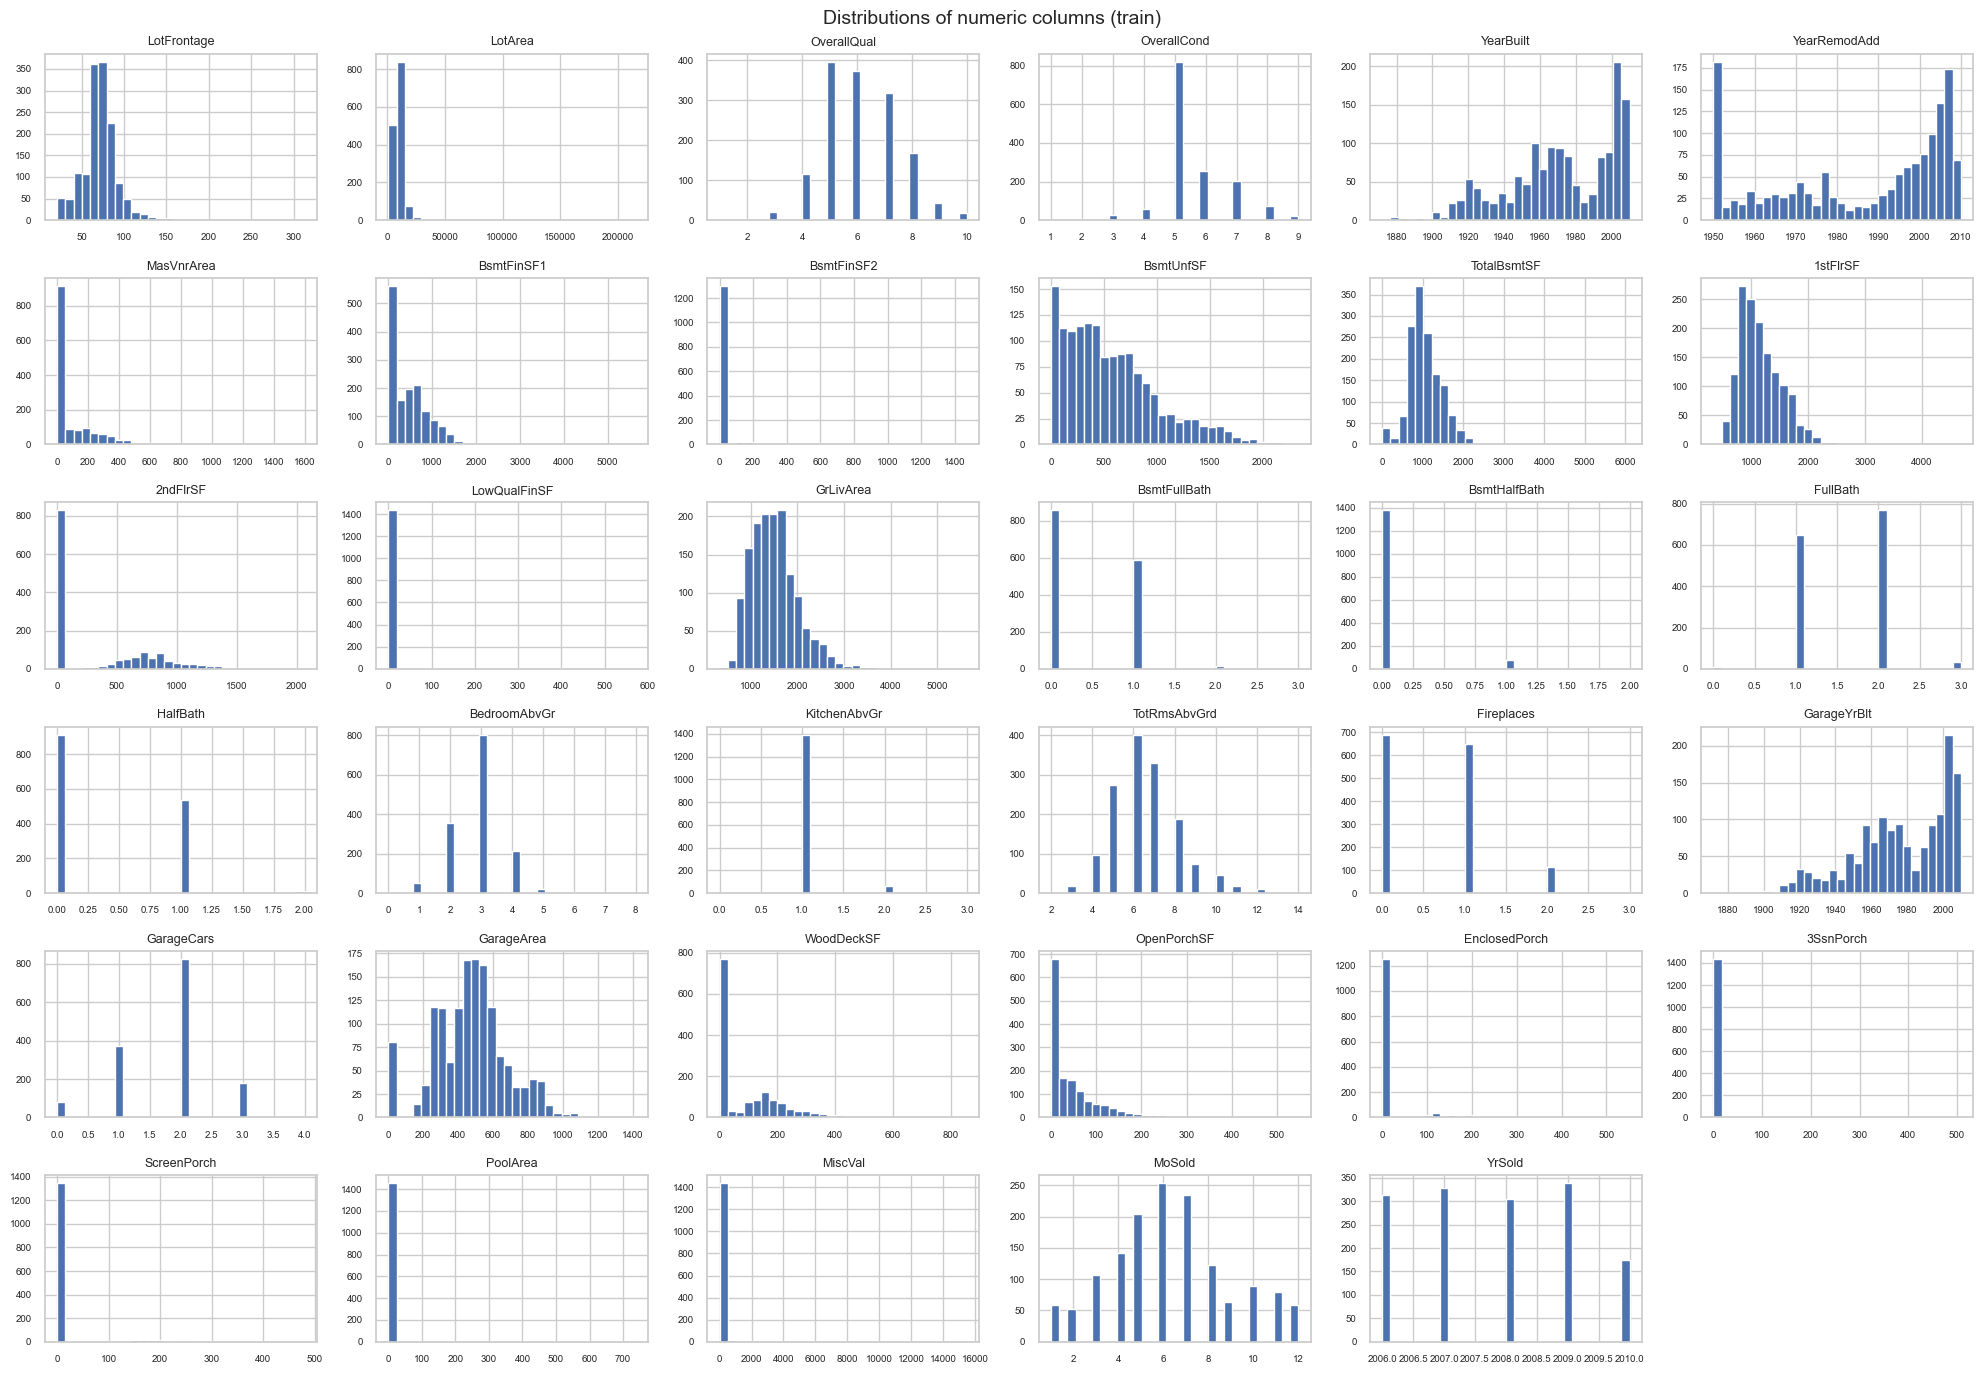

In [10]:
train_c = full.iloc[:n_train].copy()
train_c["SalePrice"] = y.values

num_plot = [c for c in num_cols if c != "MSSubClass"]
n = len(num_plot)
fig, axes = plt.subplots(int(np.ceil(n / 6)), 6, figsize=(20, 14))
for ax, c in zip(axes.flat, num_plot):
    ax.hist(train_c[c], bins=30, color="#4C72B0")
    ax.set_title(c, fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.flat[n:]:
    ax.axis("off")
plt.suptitle("Distributions of numeric columns (train)", fontsize=14)
plt.tight_layout()
plt.savefig(FIG + "03_numeric_distributions.png", dpi=100)
plt.show()

**Observations:** many area columns (`LotArea`, `GrLivArea`, `MasVnrArea`, …) are right-skewed and many have lots of zeros (no pool, no porch, no basement finish). I log-transform skewed columns in B7.

### B4.2 Correlation heatmap

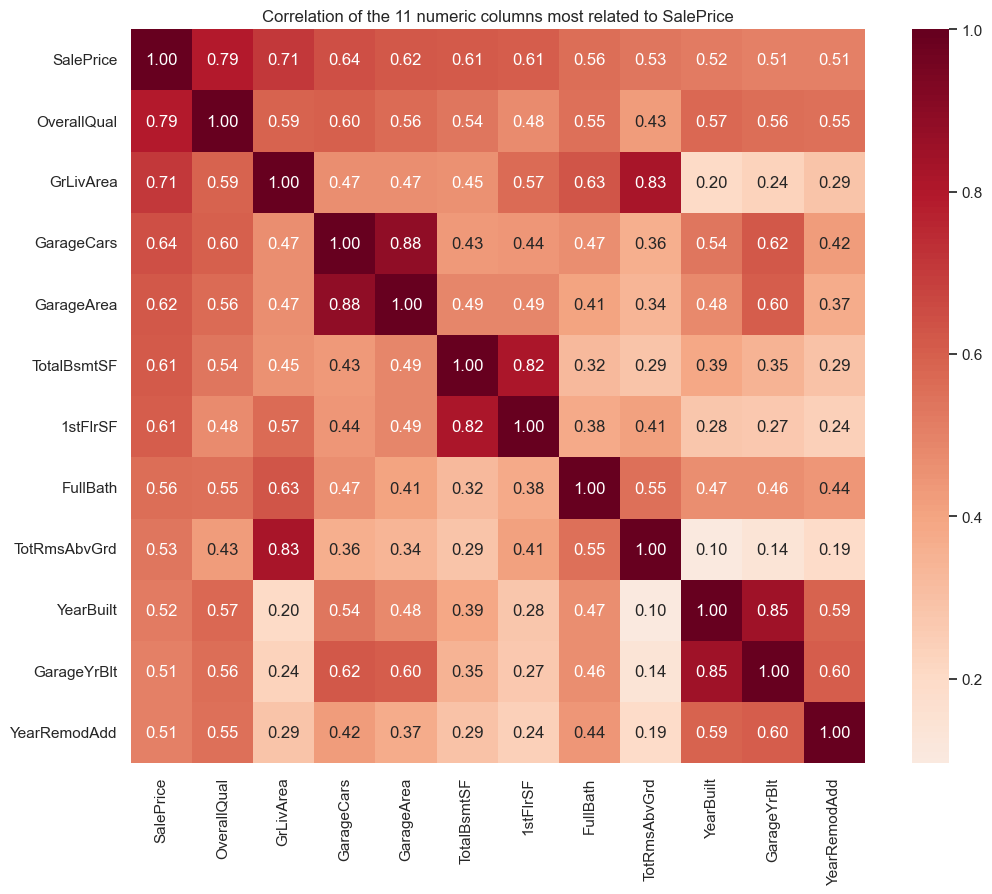

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
GarageYrBlt     0.508043
Name: SalePrice, dtype: float64

In [11]:
corr = train_c[num_cols + ["SalePrice"]].corr()
top_corr = corr["SalePrice"].abs().sort_values(ascending=False).head(12).index

plt.figure(figsize=(11, 9))
sns.heatmap(train_c[top_corr].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Correlation of the 11 numeric columns most related to SalePrice")
plt.tight_layout()
plt.savefig(FIG + "04_correlation_heatmap.png", dpi=120)
plt.show()

corr["SalePrice"].drop("SalePrice").sort_values(ascending=False).head(10)

**Observations**
- Strongest relations: `OverallQual` (0.79), `GrLivArea` (0.71), `GarageCars`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`.
- Some features are almost duplicates (multicollinearity): `GarageCars` ↔ `GarageArea` (0.88), `TotalBsmtSF` ↔ `1stFlrSF` (0.82), `GrLivArea` ↔ `TotRmsAbvGrd` (0.83). Regularized models (Ridge/Lasso) handle this.

### B4.3 Numeric columns vs SalePrice

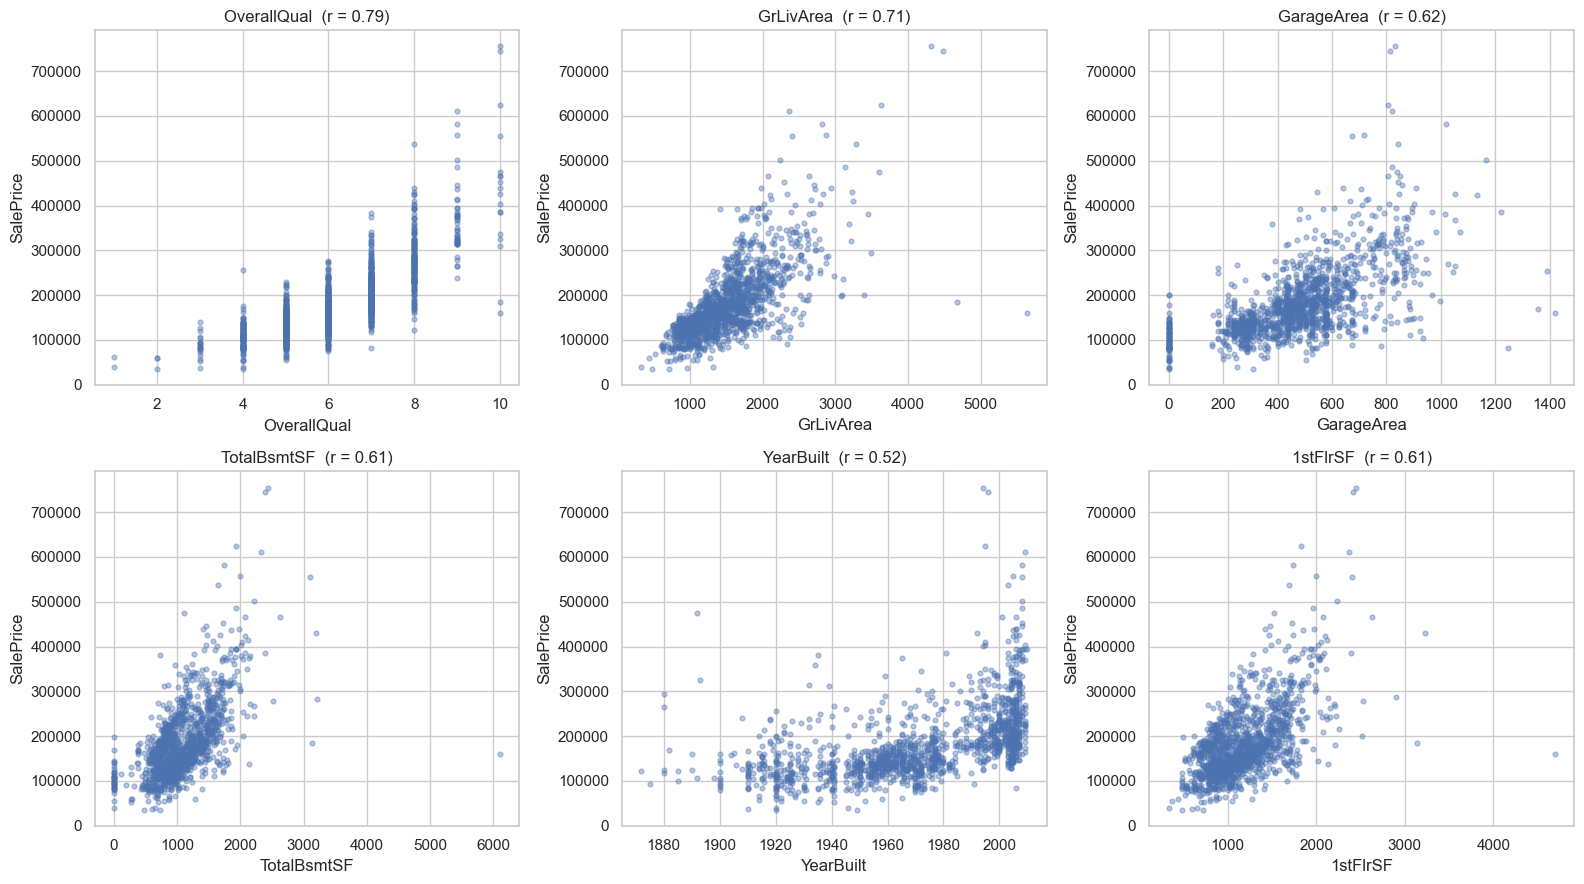

In [12]:
top_num = ["OverallQual", "GrLivArea", "GarageArea", "TotalBsmtSF", "YearBuilt", "1stFlrSF"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.flat, top_num):
    ax.scatter(train_c[c], train_c["SalePrice"], alpha=0.4, s=12)
    ax.set_xlabel(c)
    ax.set_ylabel("SalePrice")
    ax.set_title(f"{c}  (r = {corr.loc[c, 'SalePrice']:.2f})")
plt.tight_layout()
plt.savefig(FIG + "05_top_numeric_vs_price.png", dpi=110)
plt.show()

**Observations:** price grows clearly with quality and living area. In `GrLivArea` there are **2 houses with huge area but a very low price** (bottom right) — see B5.

### B4.4 Categorical columns vs SalePrice

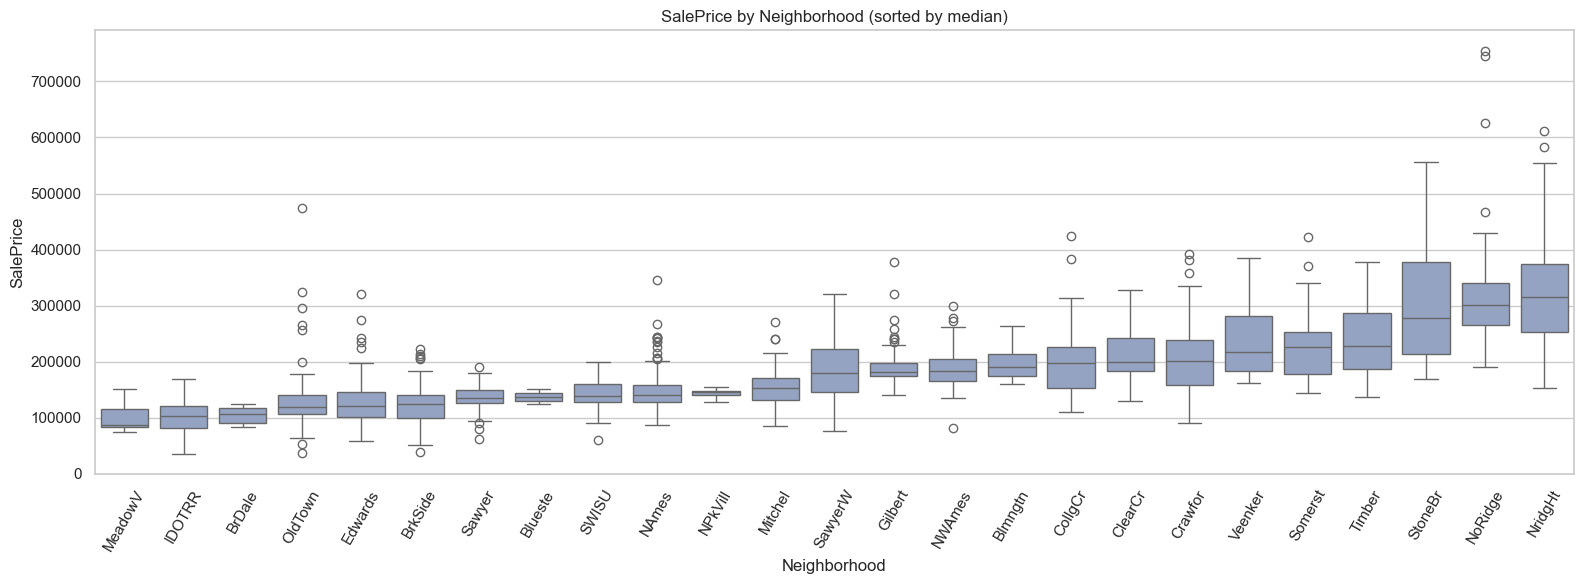

In [13]:
order = train_c.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(16, 6))
sns.boxplot(data=train_c, x="Neighborhood", y="SalePrice", order=order, color="#8DA0CB")
plt.xticks(rotation=60)
plt.title("SalePrice by Neighborhood (sorted by median)")
plt.tight_layout()
plt.savefig(FIG + "06_neighborhood_vs_price.png", dpi=110)
plt.show()

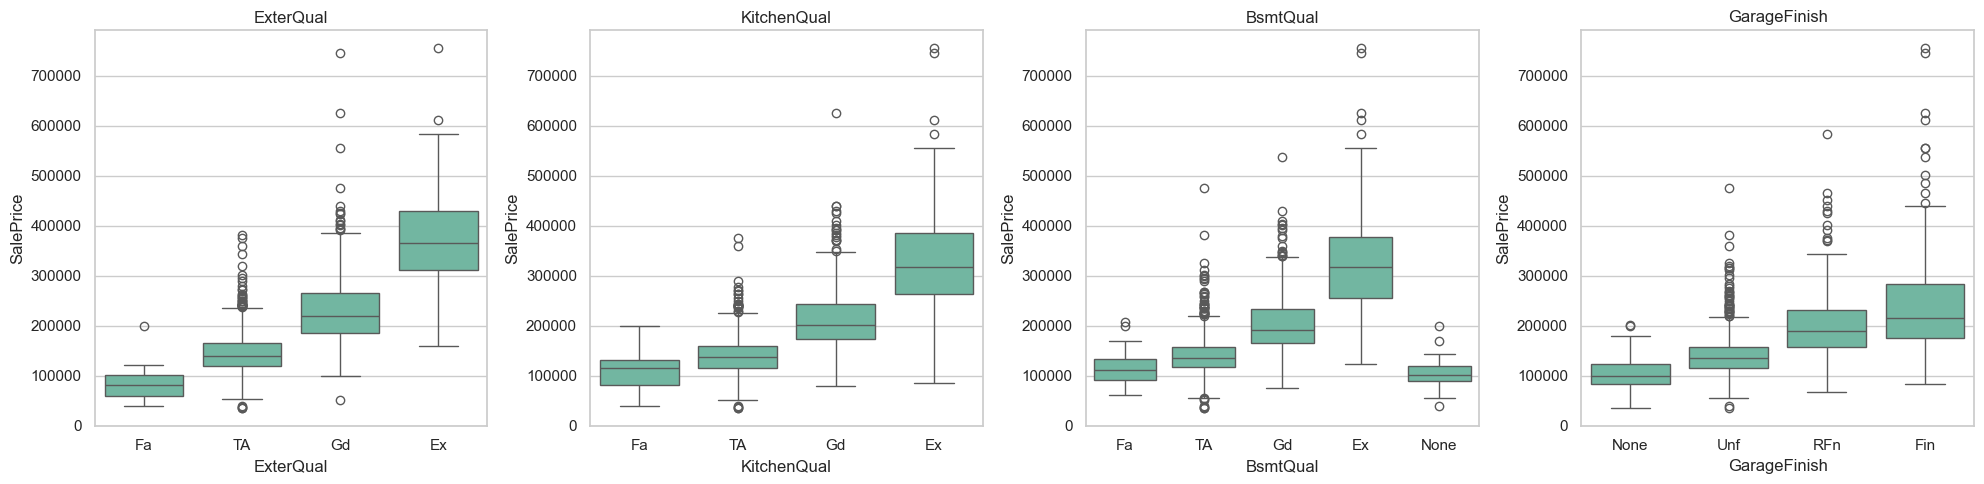

In [14]:
qual_order = ["Po", "Fa", "TA", "Gd", "Ex"]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, c in zip(axes, ["ExterQual", "KitchenQual", "BsmtQual", "GarageFinish"]):
    o = [v for v in qual_order + ["None", "Unf", "RFn", "Fin"] if v in train_c[c].unique()]
    sns.boxplot(data=train_c, x=c, y="SalePrice", order=o, ax=ax, color="#66C2A5")
    ax.set_title(c)
plt.tight_layout()
plt.savefig(FIG + "07_quality_vs_price.png", dpi=110)
plt.show()

In [15]:
cat_summary = []
for c in cat_cols:
    g = train_c.groupby(c)["SalePrice"].median()
    cat_summary.append({"column": c, "n_values": train_c[c].nunique(),
                        "most_common_share": round(train_c[c].value_counts(normalize=True).iloc[0], 3),
                        "median_price_range": int(g.max() - g.min())})
cat_summary = pd.DataFrame(cat_summary).sort_values("median_price_range", ascending=False)
cat_summary.head(15)

,column,n_values,most_common_share,median_price_range
38,PoolQC,4,0.995,327100
18,ExterQual,4,0.621,282356
10,Condition2,8,0.990,228250
8,Neighborhood,25,0.154,227000
21,BsmtQual,5,0.445,216200
16,Exterior2nd,16,0.345,214000
30,KitchenQual,4,0.503,201750
14,RoofMatl,8,0.982,195500
15,Exterior1st,15,0.353,191000
32,FireplaceQu,6,0.473,182750


**Observations**
- `Neighborhood` matters a lot: median price goes from ~90k (MeadowV) to ~280–315k (StoneBr, NoRidge, NridgHt).
- Quality columns (`ExterQual`, `KitchenQual`, `BsmtQual`) are **ordered**: Po < Fa < TA < Gd < Ex, and the price rises step by step. So I encode them as numbers 0–5 instead of one-hot.
- Some columns are almost constant (`Utilities`: 99.9 % "AllPub", `Street`: 99.6 % "Pave") — they carry no information.

## B5 · Outliers

The dataset author (Dean De Cock) recommends removing houses with `GrLivArea > 4000`. Two of them are partial sales of very big houses at a very low price — they do not follow the market.

In [16]:
outliers = train_c[(train_c["GrLivArea"] > 4000) & (train_c["SalePrice"] < 300000)]
outliers[["Id", "GrLivArea", "OverallQual", "SalePrice", "SaleCondition"]]

,Id,GrLivArea,OverallQual,SalePrice,SaleCondition
523,524,4676,10,184750,Partial
1298,1299,5642,10,160000,Partial


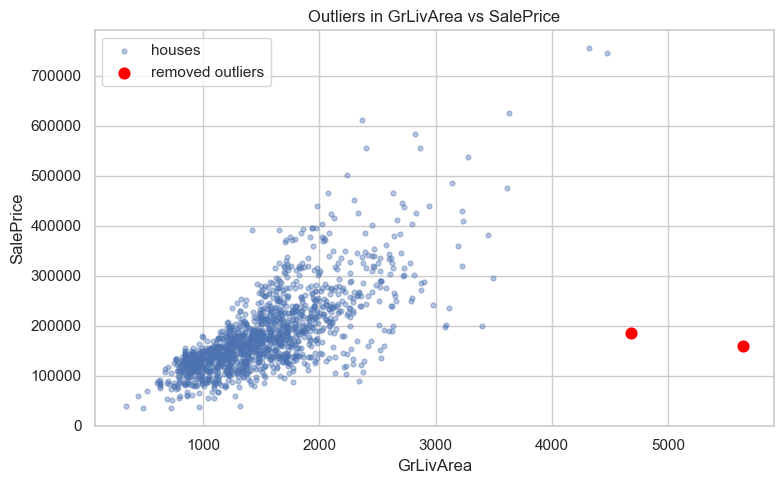

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train_c["GrLivArea"], train_c["SalePrice"], alpha=0.4, s=12, label="houses")
ax.scatter(outliers["GrLivArea"], outliers["SalePrice"], color="red", s=60, label="removed outliers")
ax.set_xlabel("GrLivArea")
ax.set_ylabel("SalePrice")
ax.legend()
ax.set_title("Outliers in GrLivArea vs SalePrice")
plt.tight_layout()
plt.savefig(FIG + "08_outliers.png", dpi=120)
plt.show()

**Decision: remove these 2 houses from train only.**
- They are huge (> 4500 sq ft) and top quality (`OverallQual` = 10) but sold for < 200k, both with `SaleCondition = Partial`.
- They would pull the regression line down for all big houses.
- The other 2 houses with `GrLivArea > 4000` have high prices, follow the trend, so I **keep** them.
- Test rows are **never** removed — we must predict every test house.

In [18]:
drop_ids = outliers["Id"].tolist()
keep = ~full.iloc[:n_train]["Id"].isin(drop_ids).values
full = pd.concat([full.iloc[:n_train][keep], full.iloc[n_train:]], ignore_index=True)
y = y[keep].reset_index(drop=True)
n_train = keep.sum()
print("train rows after removing outliers:", n_train)

train rows after removing outliers: 1458


## B6 · New features

I create 6 new columns:

| New column | Formula | Idea |
|---|---|---|
| `TotalSF` | TotalBsmtSF + 1stFlrSF + 2ndFlrSF | total area of the house |
| `TotalBath` | FullBath + 0.5·HalfBath + BsmtFullBath + 0.5·BsmtHalfBath | all bathrooms in one number |
| `HouseAge` | YrSold − YearBuilt | age at the moment of sale |
| `RemodAge` | YrSold − YearRemodAdd | years since last renovation |
| `TotalPorchSF` | OpenPorchSF + EnclosedPorch + 3SsnPorch + ScreenPorch + WoodDeckSF | all outdoor area |
| `QualSF` | OverallQual · GrLivArea | big **and** good house |

In [19]:
full["TotalSF"] = full["TotalBsmtSF"] + full["1stFlrSF"] + full["2ndFlrSF"]
full["TotalBath"] = full["FullBath"] + 0.5 * full["HalfBath"] + full["BsmtFullBath"] + 0.5 * full["BsmtHalfBath"]
full["HouseAge"] = (full["YrSold"] - full["YearBuilt"]).clip(lower=0)
full["RemodAge"] = (full["YrSold"] - full["YearRemodAdd"]).clip(lower=0)
full["TotalPorchSF"] = full[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "WoodDeckSF"]].sum(axis=1)
full["QualSF"] = full["OverallQual"] * full["GrLivArea"]

new_features = ["TotalSF", "TotalBath", "HouseAge", "RemodAge", "TotalPorchSF", "QualSF"]

**Do they help? Check 1 — correlation with log(SalePrice):** each new column vs the parts it is made of.

In [20]:
tr = full.iloc[:n_train].copy()
log_y = np.log1p(y.values)
check = {
    "TotalSF": ["TotalSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "GrLivArea"],
    "TotalBath": ["TotalBath", "FullBath", "HalfBath", "BsmtFullBath"],
    "HouseAge": ["HouseAge", "YearBuilt"],
    "RemodAge": ["RemodAge", "YearRemodAdd"],
    "TotalPorchSF": ["TotalPorchSF", "OpenPorchSF", "WoodDeckSF"],
    "QualSF": ["QualSF", "OverallQual", "GrLivArea"],
}
rows = []
for new, cols in check.items():
    for c in cols:
        rows.append({"new feature": new, "column": c, "|corr| with log price": round(abs(np.corrcoef(tr[c], log_y)[0, 1]), 3)})
pd.DataFrame(rows)

,new feature,column,|corr| with log price
0,TotalSF,TotalSF,0.825
1,TotalSF,TotalBsmtSF,0.648
2,TotalSF,1stFlrSF,0.621
3,TotalSF,2ndFlrSF,0.320
4,TotalSF,GrLivArea,0.725
5,TotalBath,TotalBath,0.677
6,TotalBath,FullBath,0.596
7,TotalBath,HalfBath,0.314
8,TotalBath,BsmtFullBath,0.237
9,HouseAge,HouseAge,0.588


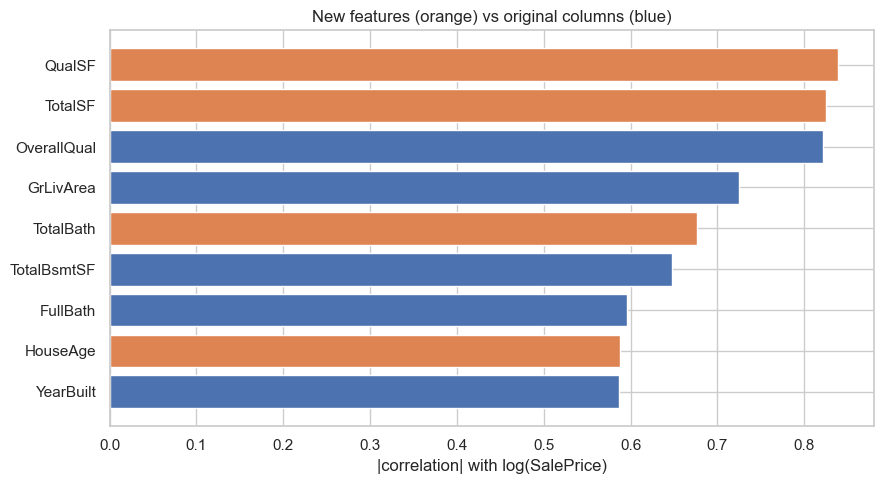

In [21]:
plt.figure(figsize=(9, 5))
cmp = pd.Series({c: abs(np.corrcoef(tr[c], log_y)[0, 1]) for c in
                 ["QualSF", "TotalSF", "OverallQual", "GrLivArea", "TotalBath", "TotalBsmtSF", "FullBath", "HouseAge", "YearBuilt"]}).sort_values()
colors = ["#DD8452" if c in new_features else "#4C72B0" for c in cmp.index]
plt.barh(cmp.index, cmp.values, color=colors)
plt.xlabel("|correlation| with log(SalePrice)")
plt.title("New features (orange) vs original columns (blue)")
plt.tight_layout()
plt.savefig(FIG + "09_new_features_correlation.png", dpi=120)
plt.show()

**Check 2 — a quick model:** 5-fold CV of a Ridge regression on the numeric columns, **without** and **with** the new features (RMSE on log price, lower is better).

In [22]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_num = [c for c in num_cols if c != "Id"]

def quick_cv(cols):
    X = np.log1p(tr[cols].clip(lower=0))
    model = make_pipeline(RobustScaler(), Ridge(alpha=10))
    return -cross_val_score(model, X, log_y, cv=kf, scoring="neg_root_mean_squared_error").mean()

rmse_without = quick_cv(base_num)
rmse_with = quick_cv(base_num + new_features)
print(f"RMSE without new features: {rmse_without:.4f}")
print(f"RMSE with new features:    {rmse_with:.4f}")
print(f"improvement:               {rmse_without - rmse_with:.4f}")

RMSE without new features: 0.1346
RMSE with new features:    0.1298
improvement:               0.0048


**Conclusion:** `TotalSF` and `QualSF` are more correlated with price than **any** original column (`QualSF` ≈ 0.84 and `TotalSF` ≈ 0.83 vs the best original, `OverallQual`, 0.82), `TotalBath` beats every single bathroom column, and the Ridge CV error goes down when the new columns are added. So the new features help.

## B7 · Select and encode

1. **Drop** columns: `Id` (just a number), `Utilities` and `Street` (almost constant), `PoolQC` / `MiscFeature` (≈ 99 % "None", the information is kept in `PoolArea` / `MiscVal`).
2. `MSSubClass`, `MoSold`, `YrSold` → treat as categories.
3. **Ordinal encoding** for quality columns: None=0, Po=1, Fa=2, TA=3, Gd=4, Ex=5 (and similar scales for basement / garage finish).
4. **log1p** of skewed numeric columns (|skew| > 0.75, ordinal scales excluded) — helps linear models.
5. **One-hot encoding** of the rest with `pd.get_dummies` on train+test **together**, so both get exactly the same columns.

In [23]:
full = full.drop(columns=["Utilities", "Street", "PoolQC", "MiscFeature"])

for c in ["MSSubClass", "MoSold", "YrSold"]:
    full[c] = full[c].astype(str)

qual_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
for c in ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
          "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond"]:
    full[c] = full[c].map(qual_map)

full["BsmtExposure"] = full["BsmtExposure"].map({"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4})
fin_map = {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}
full["BsmtFinType1"] = full["BsmtFinType1"].map(fin_map)
full["BsmtFinType2"] = full["BsmtFinType2"].map(fin_map)
full["GarageFinish"] = full["GarageFinish"].map({"None": 0, "Unf": 1, "RFn": 2, "Fin": 3})
full["Functional"] = full["Functional"].map({"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7})

print("missing after mapping:", full.isna().sum().sum())

missing after mapping: 0


In [24]:
ordinal_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
                "FireplaceQu", "GarageQual", "GarageCond", "BsmtExposure", "BsmtFinType1",
                "BsmtFinType2", "GarageFinish", "Functional"]
numeric = full.drop(columns=["Id"] + ordinal_cols).select_dtypes(include="number").columns
skews = full.iloc[:n_train][numeric].apply(lambda s: skew(s)).sort_values(ascending=False)
skewed = skews[skews.abs() > 0.75].index
skewed = [c for c in skewed if full[c].min() >= 0]
full[skewed] = np.log1p(full[skewed])
print(f"log1p applied to {len(skewed)} skewed columns:")
print(skewed)

log1p applied to 22 skewed columns:
['MiscVal', 'PoolArea', 'LotArea', '3SsnPorch', 'LowQualFinSF', 'KitchenAbvGr', 'BsmtFinSF2', 'ScreenPorch', 'BsmtHalfBath', 'EnclosedPorch', 'MasVnrArea', 'OpenPorchSF', 'LotFrontage', 'WoodDeckSF', 'QualSF', 'TotalPorchSF', 'GrLivArea', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'TotalSF', 'BsmtFinSF1']


In [25]:
ids = full["Id"]
encoded = pd.get_dummies(full.drop(columns="Id"), dtype=int)
print("columns after one-hot encoding:", encoded.shape[1])

train_processed = encoded.iloc[:n_train].copy()
test_processed = encoded.iloc[n_train:].copy()
train_processed.insert(0, "Id", ids.iloc[:n_train].values)
test_processed.insert(0, "Id", ids.iloc[n_train:].values)
train_processed["SalePrice"] = y.values

print("train_processed:", train_processed.shape)
print("test_processed: ", test_processed.shape)
assert list(train_processed.columns.drop("SalePrice")) == list(test_processed.columns)
assert train_processed.isna().sum().sum() == 0 and test_processed.isna().sum().sum() == 0
assert len(test_processed) == 1459

columns after one-hot encoding: 262
train_processed: (1458, 264)
test_processed:  (1459, 263)


In [26]:
train_processed.to_csv(PROCESSED + "train_processed.csv", index=False)
test_processed.to_csv(PROCESSED + "test_processed.csv", index=False)
print("saved to", PROCESSED)

saved to ../data/processed/


## Summary

- Target: models will use **log1p(SalePrice)**.
- All missing values filled (mostly "None"/0 as described in `data_description.txt`), using train statistics only.
- 2 outliers removed from train (`GrLivArea > 4000` with low price).
- 6 new features; they correlate with price better than the original columns and lower the CV error.
- Categories encoded identically in train and test; files saved in `data/processed/`.

Next: `02_Models.ipynb`.